In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
#%pip install Scikit-learn
from sklearn.impute import SimpleImputer
from scipy.stats import zscore
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import SelectKBest, f_classif



In [ ]:
df=pd.read_csv('https://raw.githubusercontent.com/GeethaGunasekaran1/Dataset_rep/refs/heads/main/diabetes.csv')


In [ ]:
df.head()


,Unnamed: 0,ID,No_Pation,Gender,AGE,Urea,Cr,HbA1c,Chol,TG,HDL,LDL,VLDL,BMI,CLASS
0,0,502,17975,F,50.0,4.7,46.0,4.9,4.2,0.9,2.4,1.4,0.5,24.0,N
1,1,735,34221,M,26.0,4.5,62.0,4.9,3.7,1.4,1.1,2.1,0.6,23.0,N
2,2,420,47975,F,50.0,4.7,46.0,4.9,4.2,0.9,2.4,1.4,0.5,24.0,N
3,3,680,87656,F,50.0,4.7,46.0,4.9,4.2,0.9,2.4,1.4,0.5,24.0,N
4,4,504,34223,M,33.0,7.1,46.0,4.9,4.9,1.0,0.8,2.0,0.4,21.0,N


In [ ]:
df.tail()


,Unnamed: 0,ID,No_Pation,Gender,AGE,Urea,Cr,HbA1c,Chol,TG,HDL,LDL,VLDL,BMI,CLASS
1004,1004,194,454316,F,57.0,4.1,70.0,9.3,5.3,3.3,1.0,1.4,1.3,29.0,Y
1005,1005,195,4543,f,55.0,4.1,34.0,13.9,5.4,1.6,1.6,3.1,0.7,33.0,Y
1006,1006,249,48822,M,55.0,4.2,57.0,8.9,5.3,3.1,0.7,3.3,1.4,27.0,Y
1007,1007,88,21747,M,41.0,3.8,48.0,4.3,3.2,4.5,1.3,1.8,1.1,21.0,N
1008,1008,62,46059,M,55.0,7.0,56.0,9.1,3.7,1.9,0.7,2.3,0.9,27.0,Y


In [ ]:
df.shape


(1009, 15)

In [ ]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1009 entries, 0 to 1008
Data columns (total 15 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  1009 non-null   int64  
 1   ID          1009 non-null   int64  
 2   No_Pation   1009 non-null   int64  
 3   Gender      1006 non-null   str    
 4   AGE         1008 non-null   float64
 5   Urea        1008 non-null   float64
 6   Cr          1007 non-null   float64
 7   HbA1c       1006 non-null   float64
 8   Chol        1007 non-null   float64
 9   TG          1007 non-null   float64
 10  HDL         1008 non-null   float64
 11  LDL         1007 non-null   float64
 12  VLDL        1008 non-null   float64
 13  BMI         1009 non-null   float64
 14  CLASS       1009 non-null   str    
dtypes: float64(10), int64(3), str(2)
memory usage: 118.4 KB


In [ ]:
df.dtypes


Unnamed: 0      int64
ID              int64
No_Pation       int64
Gender            str
AGE           float64
Urea          float64
Cr            float64
HbA1c         float64
Chol          float64
TG            float64
HDL           float64
LDL           float64
VLDL          float64
BMI           float64
CLASS             str
dtype: object

In [ ]:
print(f"Numerical Columns: {df.select_dtypes(include=np.number).columns.tolist()}")
print(f"Categorical Columns: {df.select_dtypes(include=str).columns.tolist()}")


Numerical Columns: ['Unnamed: 0', 'ID', 'No_Pation', 'AGE', 'Urea', 'Cr', 'HbA1c', 'Chol', 'TG', 'HDL', 'LDL', 'VLDL', 'BMI']
Categorical Columns: ['Gender', 'CLASS']


In [ ]:
df.rename(columns={
    'ID':'Visit_ID', 
    'No_Pation': 'Patient_ID'
},inplace=True)


In [10]:
print(df['Gender'].unique())
df=df.dropna(subset=['Gender'])
df['Gender']=df['Gender'].str.upper()
print(df['Gender'].unique())


<StringArray>
['F', 'M', nan, 'f']
Length: 4, dtype: str
<StringArray>
['F', 'M']
Length: 2, dtype: str


In [ ]:
print(df['CLASS'].unique())
df['CLASS']=df['CLASS'].str.strip()
print(df['CLASS'].unique())


<StringArray>
['N', 'N ', 'P', 'Y', 'Y ']
Length: 5, dtype: str
<StringArray>
['N', 'P', 'Y']
Length: 3, dtype: str


In [ ]:
num_col = df.select_dtypes(include=np.number)
num_col


,Unnamed: 0,Visit_ID,Patient_ID,AGE,Urea,Cr,HbA1c,Chol,TG,HDL,LDL,VLDL,BMI
0,0,502,17975,50.0,4.7,46.0,4.9,4.2,0.9,2.4,1.4,0.5,24.0
1,1,735,34221,26.0,4.5,62.0,4.9,3.7,1.4,1.1,2.1,0.6,23.0
2,2,420,47975,50.0,4.7,46.0,4.9,4.2,0.9,2.4,1.4,0.5,24.0
3,3,680,87656,50.0,4.7,46.0,4.9,4.2,0.9,2.4,1.4,0.5,24.0
4,4,504,34223,33.0,7.1,46.0,4.9,4.9,1.0,0.8,2.0,0.4,21.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1004,1004,194,454316,57.0,4.1,70.0,9.3,5.3,3.3,1.0,1.4,1.3,29.0
1005,1005,195,4543,55.0,4.1,34.0,13.9,5.4,1.6,1.6,3.1,0.7,33.0
1006,1006,249,48822,55.0,4.2,57.0,8.9,5.3,3.1,0.7,3.3,1.4,27.0
1007,1007,88,21747,41.0,3.8,48.0,4.3,3.2,4.5,1.3,1.8,1.1,21.0


In [ ]:
print("Statistical Summary:\n")
summary=num_col.agg(['mean','median','min','max','std']).T
print(summary)


Statistical Summary:

                     mean   median    min          max           std
Unnamed: 0     504.431412    504.5    0.0      1008.00  2.911861e+02
Visit_ID       337.977137    293.5    1.0       800.00  2.395953e+02
Patient_ID  271713.288270  34398.5  123.0  75435657.00  3.370646e+06
AGE             53.622886     55.0   25.0        79.00  8.730247e+00
Urea             5.133177      4.6    0.5        38.90  2.933528e+00
Cr              68.894422     60.0    6.0       800.00  5.989879e+01
HbA1c            8.279023      8.0    0.9        16.00  2.530371e+00
Chol             4.861175      4.8    0.0        10.30  1.290913e+00
TG               2.348416      2.0    0.3        13.80  1.397983e+00
HDL              1.203035      1.1    0.2         9.90  6.587091e-01
LDL              2.612241      2.5    0.3         9.90  1.117612e+00
VLDL             1.840000      0.9    0.1        35.00  3.637922e+00
BMI             29.580567     30.0   19.0        47.75  4.946360e+00


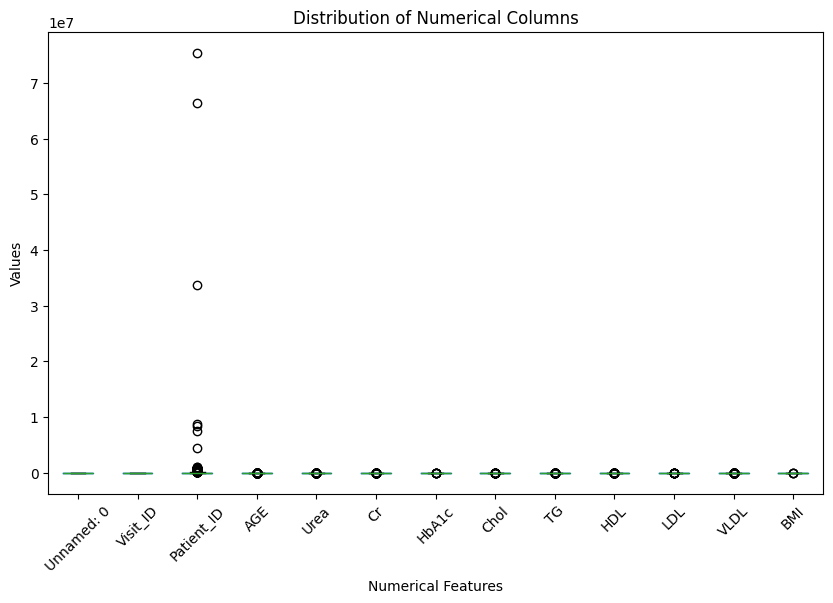

In [ ]:
plt.figure(figsize=(10,6))
num_col.boxplot(grid=False)
plt.title("Distribution of Numerical Columns")
plt.xticks(rotation=45)
plt.ylabel('Values')
plt.xlabel('Numerical Features')
plt.show()


By visualizing the numerical columns using a boxplot, we can understand if there are any outliers. It will also shows us the spread of our data in column wise. Here, we can see that except the visit_ID column, all the other columns have outliers. Patient_ID column has the most.

In [15]:
df.isnull().sum()


Unnamed: 0    0
Visit_ID      0
Patient_ID    0
Gender        0
AGE           1
Urea          1
Cr            2
HbA1c         3
Chol          2
TG            2
HDL           1
LDL           2
VLDL          1
BMI           0
CLASS         0
dtype: int64

In [16]:
num_imputer = SimpleImputer(strategy='median')
numeric_columns=df.select_dtypes(include=np.number)
df[numeric_columns.columns]=num_imputer.fit_transform(numeric_columns)



In [ ]:
numeric_columns


,Unnamed: 0,Visit_ID,Patient_ID,AGE,Urea,Cr,HbA1c,Chol,TG,HDL,LDL,VLDL,BMI
0,0,502,17975,50.0,4.7,46.0,4.9,4.2,0.9,2.4,1.4,0.5,24.0
1,1,735,34221,26.0,4.5,62.0,4.9,3.7,1.4,1.1,2.1,0.6,23.0
2,2,420,47975,50.0,4.7,46.0,4.9,4.2,0.9,2.4,1.4,0.5,24.0
3,3,680,87656,50.0,4.7,46.0,4.9,4.2,0.9,2.4,1.4,0.5,24.0
4,4,504,34223,33.0,7.1,46.0,4.9,4.9,1.0,0.8,2.0,0.4,21.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1004,1004,194,454316,57.0,4.1,70.0,9.3,5.3,3.3,1.0,1.4,1.3,29.0
1005,1005,195,4543,55.0,4.1,34.0,13.9,5.4,1.6,1.6,3.1,0.7,33.0
1006,1006,249,48822,55.0,4.2,57.0,8.9,5.3,3.1,0.7,3.3,1.4,27.0
1007,1007,88,21747,41.0,3.8,48.0,4.3,3.2,4.5,1.3,1.8,1.1,21.0


In [ ]:
df.isnull().sum()


Unnamed: 0    0
Visit_ID      0
Patient_ID    0
Gender        0
AGE           0
Urea          0
Cr            0
HbA1c         0
Chol          0
TG            0
HDL           0
LDL           0
VLDL          0
BMI           0
CLASS         0
dtype: int64

The imputation strategy used here is mean. We can choose either mean or median for imputing the numerical columns.
Since there are no null values in the Categorical Columns Gender and CLASS, i have not used the imputation step.

In [ ]:

print(df.duplicated().sum())
df=df.drop_duplicates()


0


In [20]:
lipid_cols =  ['LDL', 'VLDL', 'HDL', 'TG', 'Chol']
z_scores = np.abs(df[lipid_cols].apply(zscore))
df_cleaned = df[(z_scores < 3).all(axis=1)]


In [ ]:
for col in lipid_cols:
    z=np.abs(zscore(df[col]))
    print(f"{col}: {(z>3).sum()} outliers")


LDL: 7 outliers
VLDL: 29 outliers
HDL: 15 outliers
TG: 17 outliers
Chol: 18 outliers


In [ ]:
print("Original shape:", df.shape)
print("Cleaned shape:", df_cleaned.shape)
print("Rows removed:", df.shape[0] - df_cleaned.shape[0])


Original shape: (1006, 15)
Cleaned shape: (928, 15)
Rows removed: 78


In [ ]:
percentile_Cr= np.percentile(df['Cr'],99.5)
percentile_Urea= np.percentile(df['Urea'],99.9)
print(percentile_Cr)
print(percentile_Urea)


401.0
26.388000000000282


In [ ]:
count_cr=(df['Cr']>=400).sum()
count_Urea = (df['Urea']>= 26.3).sum()
print(count_cr)
print(count_Urea)


7
2


In [ ]:
cleaned_Cr=df['Cr'][(df['Cr'] < percentile_Cr)]


In [ ]:
cleaned_Urea= df['Urea'][(df['Urea'] < percentile_Urea)]


The Outliers in Lipid data coulmns were removed using the Z-score values

The Outliers in Cr and Urea Column were removed using the Percentile position for 99.5 and 99.2. The values greater than those are removed successfully.

The Outliers in AGE,HbA1c and BMI columns are asked to be retained. Extremely young or elderly patients are valid observations. Patient with age 95+ is rare but still a valid one in medical terms.

HbA1C values - Higher HbA1C values indicate severity of Diabetes. Removing them will eliminate high risk patients data

BMI - Higher BMI values are also related to severity of Diabetes. Lower ones indicate underweight conditions. patient with High BMI means he is severly obese and need proper treatment. So these datas must be retained.

In [ ]:
le = LabelEncoder()
df['Gender_Encoded'] = le.fit_transform(df['Gender'])
print(dict(zip(le.classes_,le.transform(le.classes_))))


{'F': np.int64(0), 'M': np.int64(1)}


In [ ]:
le = LabelEncoder()
df['CLASS_Encoded'] = le.fit_transform(df['CLASS'])
print(dict(zip(le.classes_,le.transform(le.classes_))))


{'N': np.int64(0), 'P': np.int64(1), 'Y': np.int64(2)}


In [29]:
X=df.drop(['CLASS','Gender','CLASS_Encoded','Unnamed: 0'],axis=1)
y=df['CLASS_Encoded']
selector=SelectKBest(score_func = f_classif,k=5)
X_new= selector.fit_transform(X,y)


In [ ]:
selected_columns = X.columns[selector.get_support()]

print(selected_columns)


Index(['AGE', 'HbA1c', 'Chol', 'TG', 'BMI'], dtype='str')


In [ ]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X_new,y,test_size=0.2,random_state=42)


In [ ]:
X_train.shape


(804, 5)

In [ ]:
X_test.shape


(202, 5)

Since I have retained outliers in certain columns, i am choosing Standardization as the scaling method. MIn Max scaler is sensitive to outliers. 

In [34]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_trained_Scaled = scaler.fit_transform(X_train)
X_tested_Scaled = scaler.transform(X_test)


In [ ]:
X_trained_Scaled


array([[-1.08821341, -1.67215976,  0.62239304, -0.7194094 , -1.50830123],
       [-0.06357942, -0.52963862,  0.46363038,  1.22641752,  1.88919462],
       [ 0.27796525, -0.09626853,  0.22548641,  0.17242794, -0.70889044],
       ...,
       [ 0.73335813, -0.52963862, -0.96523348, -1.20586614, -0.30918505],
       [ 0.0502688 , -0.01747397, -1.99719071, -1.28694226,  0.88993113],
       [-2.22669562, -0.88421415,  1.09868099,  1.30749364, -1.30844853]],
      shape=(804, 5))

In [ ]:
X_tested_Scaled


array([[-0.29127586,  1.87359551,  1.17806232,  3.98300566,  1.08978383],
       [ 0.0502688 ,  1.51901998, -0.96523348,  2.2804071 ,  0.09052035],
       [ 0.73335813,  1.75540367, -0.25080155, -0.15187655,  1.28963653],
       ...,
       [ 0.39181347, -0.5690359 ,  1.01929966,  3.0100922 ,  1.48948922],
       [-0.06357942,  0.49469068,  1.89249425, -0.23295267,  0.49022574],
       [-0.40512408, -1.27818695, -0.33018287,  0.33458018, -1.70815393]],
      shape=(202, 5))